# AlphaGenome 2 — HEK293T ATAC-seq signal distributions

**Analysis:** 20,000 randomly sampled genomic windows of 250 bp for each of 14 genomes.  
**Human reference control:** *Homo sapiens*, GRCh38.p14 / hg38 (`GCF_000001405.40`).  
**Assay:** ATAC-seq, HEK293T (`EFO:0001184`), observed track.  

The BigWig sampling has **already been run** by `src/analyze_atac_signal.py`. This notebook reads the saved results; it does not rerun AlphaGenome 2 or resample the genomes.

**Interpretation caution:** This is a comparison of *model-predicted* accessibility signals across species. AlphaGenome 2 is trained on human and mouse contexts, so nonhuman results are exploratory and should not be treated as experimentally measured chromatin accessibility.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path(
    "/media/eternus1/nfs/projects/dpanchenko/alphagenome2_genome_pipeline"
)
ANALYSIS_DIR = PROJECT_ROOT / "analysis" / "atac_hek293t"
FIGURES_DIR = ANALYSIS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SAMPLES_CSV = ANALYSIS_DIR / "sampled_regions.csv"
SUMMARY_CSV = ANALYSIS_DIR / "signal_summary.csv"
SETTINGS_JSON = ANALYSIS_DIR / "sampling_settings.json"
INVENTORY_CSV = PROJECT_ROOT / "inventory" / "atac_hek293t_subset.csv"

for file in (SAMPLES_CSV, SUMMARY_CSV, SETTINGS_JSON, INVENTORY_CSV):
    if not file.is_file():
        raise FileNotFoundError(f"Missing required input: {file}")

print("Project:", PROJECT_ROOT)
print("Analysis:", ANALYSIS_DIR)

Project: /media/eternus1/nfs/projects/dpanchenko/alphagenome2_genome_pipeline
Analysis: /media/eternus1/nfs/projects/dpanchenko/alphagenome2_genome_pipeline/analysis/atac_hek293t


## 1. Load and validate sampled-region data

Each row represents one 250 bp genomic window. `mean_signal` is the mean of finite per-base BigWig values. The preprocessing script records `coverage_fraction` and `fully_covered` so missing signal is distinguishable from genuine zero signal.

In [2]:
samples = pd.read_csv(SAMPLES_CSV)
summary = pd.read_csv(SUMMARY_CSV)
settings = json.loads(SETTINGS_JSON.read_text(encoding="utf-8"))
inventory = pd.read_csv(INVENTORY_CSV)

required = {
    "species_id", "chromosome", "start", "end", "mean_signal",
    "coverage_fraction", "fully_covered", "human_control",
}
if not required.issubset(samples.columns):
    raise ValueError(f"Missing sampled-region columns: {sorted(required - set(samples.columns))}")

species_order = inventory["species_id"].tolist()
CONTROL = "Homo_sapiens"
if len(species_order) != 14 or len(set(species_order)) != 14 or CONTROL not in species_order:
    raise ValueError("The inventory must contain 14 distinct species including Homo_sapiens")
if set(samples["species_id"]) != set(species_order):
    raise ValueError("Sampled species do not match the inventory")

expected_samples = int(settings["samples_per_genome"])
expected_width = int(settings["region_width_bp"])
counts = samples.groupby("species_id").size().reindex(species_order)
if not (counts == expected_samples).all():
    raise ValueError(f"Unexpected region counts per species:\n{counts}")
if not ((samples["end"] - samples["start"]) == expected_width).all():
    raise ValueError("Sampled regions do not all have the expected width")

print("Total sampled regions:", f"{len(samples):,}")
print("Genomes:", len(species_order))
print("Samples per genome:", f"{expected_samples:,}")
print("Region width:", expected_width, "bp")
print("Random seed:", settings["random_seed"])
print("Human control:", CONTROL)
display(summary.set_index("species_id").reindex(species_order).reset_index())

Total sampled regions: 280,000
Genomes: 14
Samples per genome: 20,000
Region width: 250 bp
Random seed: 42
Human control: Homo_sapiens


,species_id,sampled_regions,fully_covered_regions,mean_signal,median_signal,p95_signal,zero_fraction,human_control
0,Apis_mellifera,20000,20000,0.010098,0.003828,0.033584,0.0,False
1,Biomphalaria_glabrata,20000,20000,0.017547,0.010472,0.044372,0.0,False
2,Caenorhabditis_briggsae,20000,20000,0.012872,0.004617,0.031803,0.0,False
3,Caenorhabditis_elegans,20000,20000,0.016451,0.006856,0.042428,0.0,False
4,Crassostrea_gigas,20000,20000,0.014969,0.008325,0.041701,0.0,False
5,Drosophila_melanogaster,20000,20000,0.020269,0.008918,0.062278,0.0,False
6,Drosophila_simulans,20000,20000,0.020968,0.009542,0.067075,0.0,False
7,Drosophila_yakuba,20000,20000,0.018851,0.008701,0.059740,0.0,False
8,Nasonia_vitripennis,20000,20000,0.014725,0.005255,0.053304,0.0,False
9,Octopus_bimaculoides,20000,20000,0.008637,0.005924,0.026244,0.0,False


## 2. Quality control and transformation

The main comparisons use **fully covered** 250 bp windows with finite means. Zero values are retained as genuine zeros. Incomplete windows and NaNs are excluded from the plotted distributions, not silently turned into zero.

For visualization we use `log1p(mean_signal)` if all finite signals are nonnegative; otherwise we use `asinh(mean_signal)`, which also handles negative values. Statistics in the original CSV retain the **untransformed** signal.

In [3]:
quality = (
    samples.assign(
        usable=samples["fully_covered"].eq(True)
        & np.isfinite(samples["mean_signal"])
    )
    .groupby("species_id", sort=False)
    .agg(sampled=("mean_signal", "size"), usable=("usable", "sum"))
    .reindex(species_order)
)
quality["excluded"] = quality["sampled"] - quality["usable"]
quality["usable_fraction"] = quality["usable"] / quality["sampled"]
display(quality)

usable = samples.loc[
    samples["fully_covered"].eq(True)
    & np.isfinite(samples["mean_signal"])
].copy()
if usable.empty or CONTROL not in set(usable["species_id"]):
    raise ValueError("No valid samples, or human control samples missing")

use_log1p = bool((usable["mean_signal"] >= 0).all())
if use_log1p:
    usable["plot_signal"] = np.log1p(usable["mean_signal"].to_numpy())
    X_LABEL = "log1p(mean ATAC signal per 250 bp window)"
else:
    usable["plot_signal"] = np.arcsinh(usable["mean_signal"].to_numpy())
    X_LABEL = "asinh(mean ATAC signal per 250 bp window)"

print("Visualization transformation:", "log1p" if use_log1p else "asinh")
print("Excluded windows:", f"{len(samples) - len(usable):,}")

# Shared x-axis limits: percentile trimming applies only to visualization.
x_low, x_high = np.quantile(usable["plot_signal"], [0.001, 0.995])
if x_high <= x_low:
    x_high = x_low + 1.0
bins = np.linspace(x_low, x_high, 55)

,sampled,usable,excluded,usable_fraction
species_id,,,,
Apis_mellifera,20000,20000,0,1.0
Biomphalaria_glabrata,20000,20000,0,1.0
Caenorhabditis_briggsae,20000,20000,0,1.0
Caenorhabditis_elegans,20000,20000,0,1.0
Crassostrea_gigas,20000,20000,0,1.0
Drosophila_melanogaster,20000,20000,0,1.0
Drosophila_simulans,20000,20000,0,1.0
Drosophila_yakuba,20000,20000,0,1.0
Nasonia_vitripennis,20000,20000,0,1.0


Visualization transformation: log1p
Excluded windows: 0


## 3. Signal summaries and comparison with human

The table below compares raw signal statistics. `median_minus_human` is a difference, not a fold change, so it remains defined when the human median is zero.

In [4]:
stats = usable.groupby("species_id")["mean_signal"].agg(
    n="size",
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max",
)
stats["p95"] = usable.groupby("species_id")["mean_signal"].quantile(0.95)
stats["zero_fraction"] = usable.groupby("species_id")["mean_signal"].apply(
    lambda x: float((x == 0).mean())
)

human_median = float(stats.loc[CONTROL, "median"])
stats["median_minus_human"] = stats["median"] - human_median
stats = stats.reindex(species_order)
display(stats.round(5))

print("Human median signal:", human_median)
print("Human mean signal:", float(stats.loc[CONTROL, "mean"]))

,n,mean,median,std,min,max,p95,zero_fraction,median_minus_human
species_id,,,,,,,,,
Apis_mellifera,20000,0.01010,0.00383,0.02915,0.00000,0.87283,0.03358,0.0,-0.00838
Biomphalaria_glabrata,20000,0.01755,0.01047,0.04479,0.00002,2.30825,0.04437,0.0,-0.00173
Caenorhabditis_briggsae,20000,0.01287,0.00462,0.06648,0.00000,3.58750,0.03180,0.0,-0.00759
Caenorhabditis_elegans,20000,0.01645,0.00686,0.06311,0.00001,2.18384,0.04243,0.0,-0.00535
Crassostrea_gigas,20000,0.01497,0.00832,0.03711,0.00005,1.77662,0.04170,0.0,-0.00388
Drosophila_melanogaster,20000,0.02027,0.00892,0.05742,0.00000,1.88465,0.06228,0.0,-0.00329
Drosophila_simulans,20000,0.02097,0.00954,0.05672,0.00007,2.09101,0.06708,0.0,-0.00267
Drosophila_yakuba,20000,0.01885,0.00870,0.05187,0.00001,1.78909,0.05974,0.0,-0.00351
Nasonia_vitripennis,20000,0.01472,0.00525,0.04806,0.00003,3.35307,0.05330,0.0,-0.00695


Human median signal: 0.012206905055791101
Human mean signal: 0.032808096756632106


## 4. Histograms — all 14 genomes

All panels use **identical bins and axes** for comparisons. The plotted upper tail is clipped to the common axis limits for readability, but the original values and statistics are not modified.

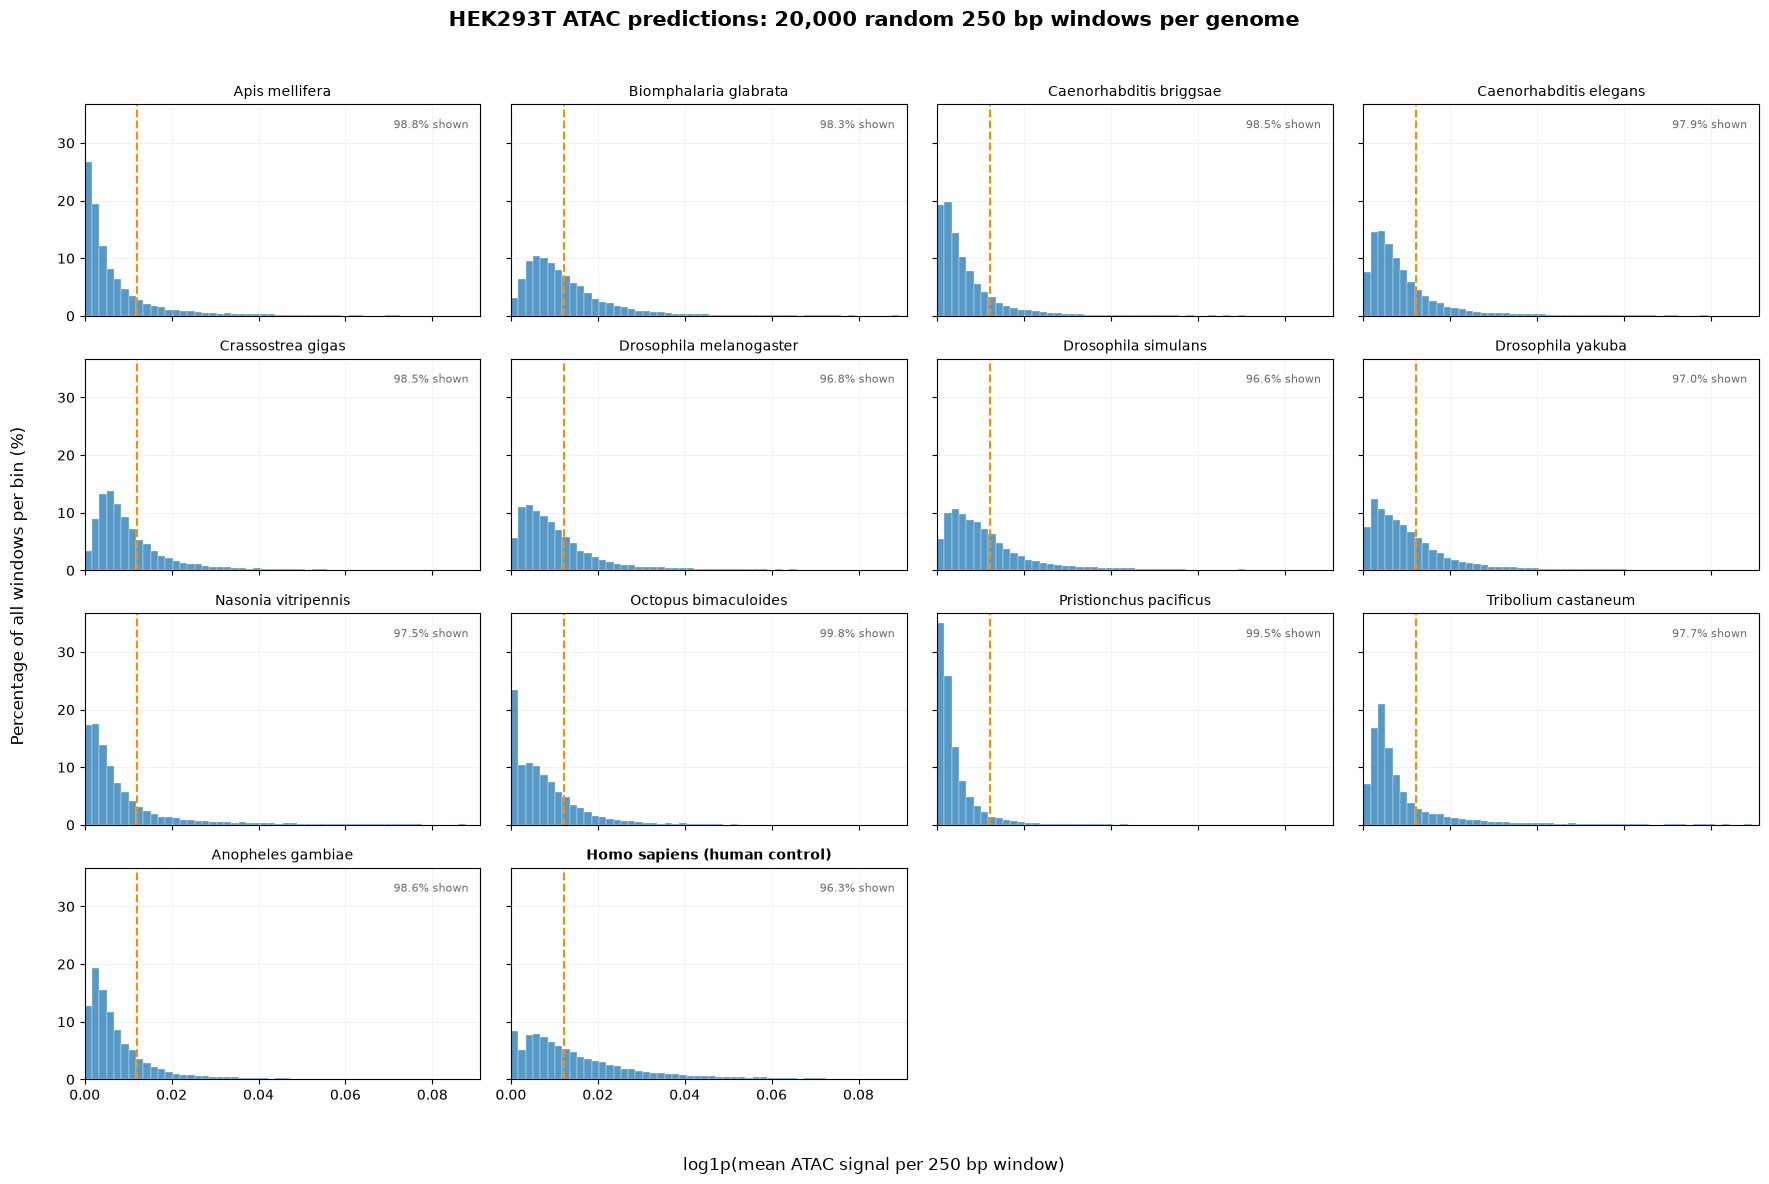

In [8]:

# Shared zoom range for histograms and ECDF plots
x_zoom = float(np.percentile(usable["plot_signal"].dropna(), 98))
bins_zoom = np.linspace(0, x_zoom, 55)

human_values = usable.loc[
    usable["species_id"] == CONTROL, "plot_signal"
].to_numpy()
human_median = np.median(human_values)

fig, axes = plt.subplots(
    4, 4, figsize=(18, 12), sharex=True, sharey=True
)

for ax, species in zip(axes.flat, species_order):
    values = usable.loc[
        usable["species_id"] == species, "plot_signal"
    ].to_numpy()

    # Percentage of ALL sampled windows per bin.
    # Values outside the zoom are not renormalized.
    ax.hist(
        values,
        bins=bins_zoom,
        weights=np.full(len(values), 100 / len(values)),
        alpha=0.75,
        edgecolor="white",
        linewidth=0.3,
    )

    ax.axvline(
        human_median,
        color="darkorange",
        linestyle="--",
        linewidth=1.5,
    )

    shown_pct = 100 * np.mean(values <= x_zoom)

    ax.text(
        0.97, 0.93,
        f"{shown_pct:.1f}% shown",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        color="dimgray",
    )

    title = species.replace("_", " ")
    if species == CONTROL:
        title += " (human control)"
        ax.set_title(title, fontsize=10, fontweight="bold")
    else:
        ax.set_title(title, fontsize=10)

    ax.set_xlim(0, x_zoom)
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)

for ax in list(axes.flat)[len(species_order):]:
    ax.set_visible(False)

fig.supxlabel(X_LABEL)
fig.supylabel("Percentage of all windows per bin (%)")
fig.suptitle(
    "HEK293T ATAC predictions: 20,000 random 250 bp windows per genome",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout(rect=(0.02, 0.03, 1, 0.96))
fig.savefig(
    FIGURES_DIR / "atac_histograms_14_genomes.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


## 5. Empirical CDFs — each genome versus hg38

Each panel compares one nonhuman species with the same **human control distribution** (dashed curve). An ECDF shows the fraction of sampled windows at or below a signal value, including any mass at zero.

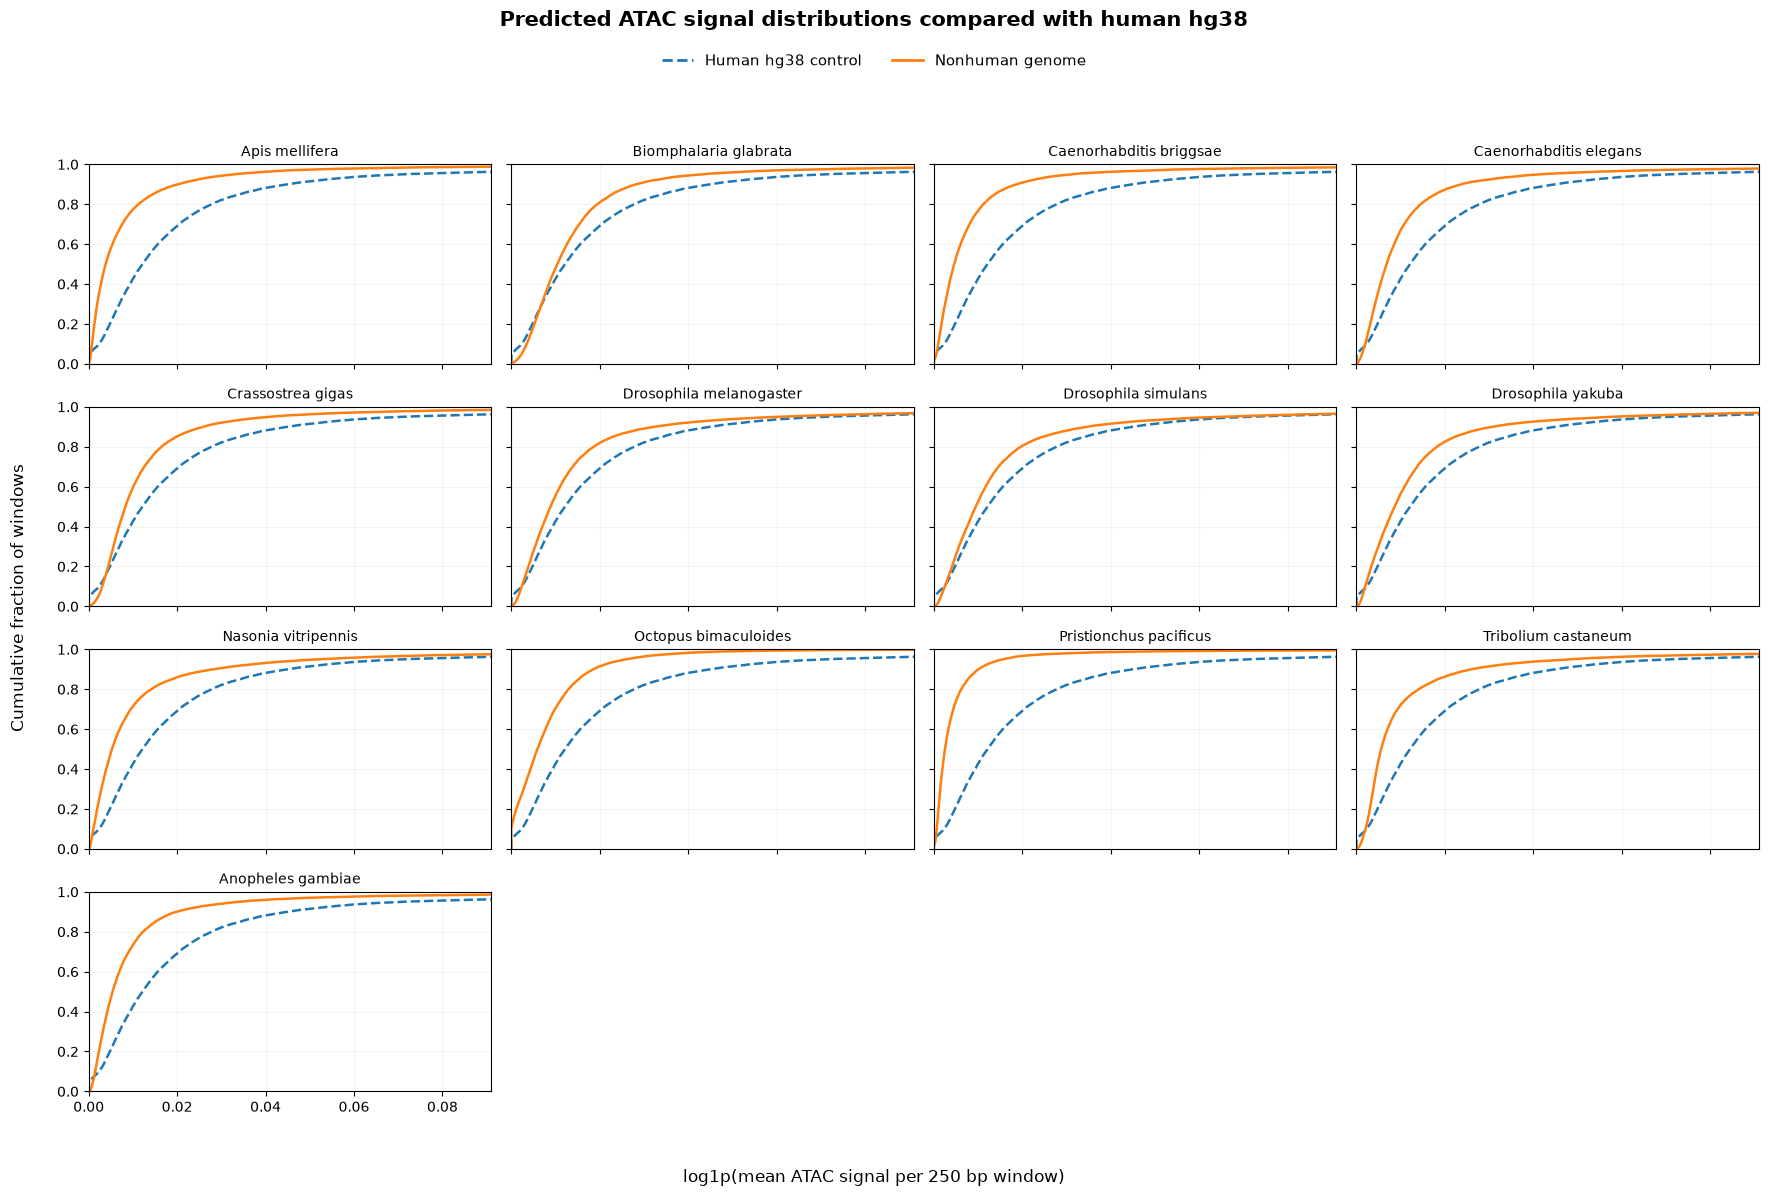

In [9]:

from matplotlib.lines import Line2D

def ecdf(values):
    ordered = np.sort(np.asarray(values, dtype=float))
    fraction = np.arange(1, len(ordered) + 1) / len(ordered)
    return ordered, fraction

control_values = usable.loc[
    usable["species_id"] == CONTROL, "plot_signal"
].to_numpy()

h_x, h_y = ecdf(control_values)
nonhuman = [s for s in species_order if s != CONTROL]

fig, axes = plt.subplots(
    4, 4, figsize=(18, 12), sharex=True, sharey=True
)

for ax, species in zip(axes.flat, nonhuman):
    values = usable.loc[
        usable["species_id"] == species, "plot_signal"
    ].to_numpy()

    s_x, s_y = ecdf(values)

    ax.plot(
        h_x, h_y,
        linestyle="--",
        linewidth=1.8,
        color="tab:blue",
    )

    ax.plot(
        s_x, s_y,
        linewidth=1.8,
        color="tab:orange",
    )

    ax.set_xlim(0, x_zoom)
    ax.set_ylim(0, 1)

    ax.set_title(species.replace("_", " "), fontsize=10)
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)

for ax in list(axes.flat)[len(nonhuman):]:
    ax.set_visible(False)

legend_handles = [
    Line2D(
        [0], [0],
        color="tab:blue",
        linestyle="--",
        linewidth=2,
        label="Human hg38 control",
    ),
    Line2D(
        [0], [0],
        color="tab:orange",
        linewidth=2,
        label="Nonhuman genome",
    ),
]

fig.suptitle(
    "Predicted ATAC signal distributions compared with human hg38",
    fontsize=15,
    fontweight="bold",
    y=0.99,
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=2,
    frameon=False,
    fontsize=11,
)

fig.supxlabel(X_LABEL)
fig.supylabel("Cumulative fraction of windows")

fig.tight_layout(rect=(0.02, 0.03, 1, 0.92))

fig.savefig(
    FIGURES_DIR / "atac_ecdf_vs_human.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


## 6. Boxplots — cross-genome overview

Boxplots show medians and interquartile ranges on the transformed scale. Extreme observations are omitted from the drawing (`showfliers=False`), not from the source data or statistics.

/tmp/ipykernel_1906419/3909958597.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(


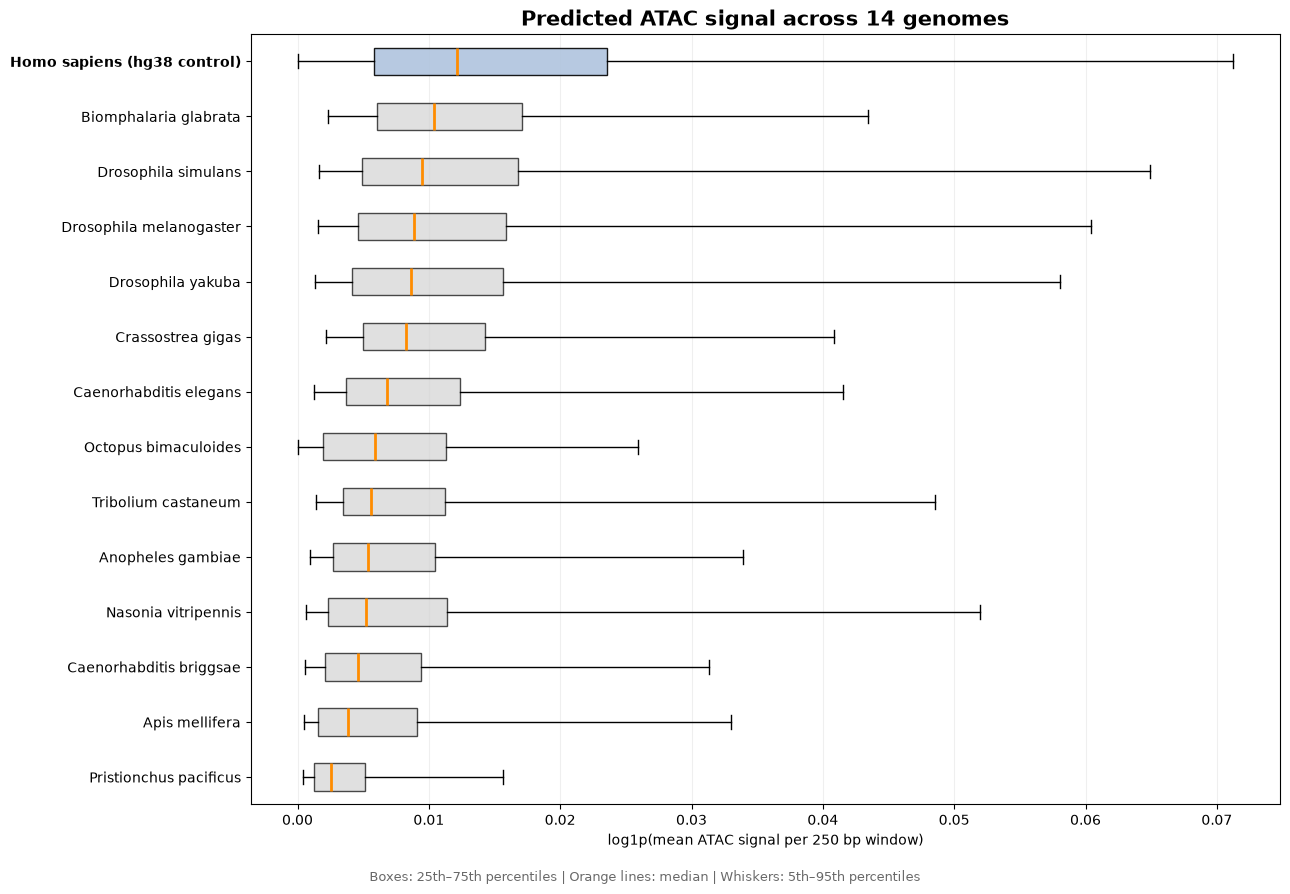

In [10]:

# Sort nonhuman genomes by median predicted signal
medians = usable.groupby("species_id")["plot_signal"].median()

nonhuman_sorted = sorted(
    [s for s in species_order if s != CONTROL],
    key=lambda s: medians[s],
)

# Human appears at the top of the horizontal boxplot
box_order = nonhuman_sorted + [CONTROL]

box_values = [
    usable.loc[
        usable["species_id"] == species, "plot_signal"
    ].to_numpy()
    for species in box_order
]

labels = [
    species.replace("_", " ")
    + (" (hg38 control)" if species == CONTROL else "")
    for species in box_order
]

fig, ax = plt.subplots(figsize=(13, 9))

bp = ax.boxplot(
    box_values,
    vert=False,
    showfliers=False,
    whis=(5, 95),
    patch_artist=True,
    medianprops={"color": "darkorange", "linewidth": 2},
    boxprops={"linewidth": 1},
)

# Highlight the human control
for i, box in enumerate(bp["boxes"]):
    if box_order[i] == CONTROL:
        box.set_facecolor("lightsteelblue")
        box.set_alpha(0.9)
    else:
        box.set_facecolor("lightgray")
        box.set_alpha(0.7)

ax.set_yticks(
    range(1, len(box_order) + 1),
    labels,
)

# Emphasize human-control label
ax.get_yticklabels()[-1].set_fontweight("bold")

ax.set_xlabel(X_LABEL)
ax.set_title(
    "Predicted ATAC signal across 14 genomes",
    fontsize=15,
    fontweight="bold",
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.015,
    "Boxes: 25th–75th percentiles | "
    "Orange lines: median | "
    "Whiskers: 5th–95th percentiles",
    ha="center",
    fontsize=9,
    color="dimgray",
)

fig.tight_layout(rect=(0, 0.035, 1, 1))

fig.savefig(
    FIGURES_DIR / "atac_boxplot_14_genomes.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


## 7. Conclusions and limitations

**Study design:** 20,000 independently sampled 250 bp windows per genome, with sampling weighted by the number of eligible start positions on each chromosome. A fixed seed (`42`) permits reproducibility of the saved analysis.

**Human reference:** hg38 / GRCh38.p14 is the in-distribution genomic control for the human HEK293T ATAC model. The same region-sampling and signal-statistics procedure was applied to all 14 genomes.

**Important limitations:**

- Nonhuman outputs are **cross-species predictions** from a human/mouse-trained model. Their numerical signals are not necessarily calibrated between species.
- Differences in genomic composition, assembly quality, eligible-contig selection, and effective genome length can affect observed distributions.
- Random windows summarize the overall predicted signal landscape; they do not prove that particular loci are experimentally active.
- Sampling windows are drawn with replacement. Some overlap or repeat is possible; this is appropriate for the stated random-sampling design.

**Next analyses:** Compare signal enrichment near annotated promoters or experimentally measured accessible regions, if suitable organism-specific reference data become available.

The figures are written to `analysis/atac_hek293t/figures/` on the `aglab` server.